In [1]:
from google.colab import drive

drive.mount('/content/drive')
path = '/content/drive/MyDrive/Datasheet/movies_metadata.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd

df = pd.read_csv(path)
df.info()

/tmp/ipykernel_3353/3766738840.py:3: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-null  object 
 15  re

In [3]:
# Cek kolom adult, apakah layak untuk dijadikan fitur
df['adult'].nunique()

5

In [4]:
df['adult'].unique()

array(['False', 'True', ' - Written by Ørnås',
       ' Rune Balot goes to a casino connected to the October corporation to try to wrap up her case once and for all.',
       ' Avalanche Sharks tells the story of a bikini contest that turns into a horrifying affair when it is hit by a shark avalanche.'],
      dtype=object)

In [5]:
df['adult'].value_counts(dropna=False)

,count
adult,
False,45454
True,9
- Written by Ørnås,1
Rune Balot goes to a casino connected to the October corporation to try to wrap up her case once and for all.,1
Avalanche Sharks tells the story of a bikini contest that turns into a horrifying affair when it is hit by a shark avalanche.,1


In [6]:
df.groupby('adult')['revenue'].agg(
    ['count','median','mean']
)

,count,median,mean
adult,,,
- Written by Ørnås,0,NaN,NaN
Avalanche Sharks tells the story of a bikini contest that turns into a horrifying affair when it is hit by a shark avalanche.,0,NaN,NaN
Rune Balot goes to a casino connected to the October corporation to try to wrap up her case once and for all.,0,NaN,NaN
False,45451,0.0,1.121157e+07
True,9,0.0,0.000000e+00


In [7]:
# Pengecekan fitur untuk belogns_to_collection
df['belongs_to_collection'].unique()

array(["{'id': 10194, 'name': 'Toy Story Collection', 'poster_path': '/7G9915LfUQ2lVfwMEEhDsn3kT4B.jpg', 'backdrop_path': '/9FBwqcd9IRruEDUrTdcaafOMKUq.jpg'}",
       nan,
       "{'id': 119050, 'name': 'Grumpy Old Men Collection', 'poster_path': '/nLvUdqgPgm3F85NMCii9gVFUcet.jpg', 'backdrop_path': '/hypTnLot2z8wpFS7qwsQHW1uV8u.jpg'}",
       ...,
       "{'id': 148603, 'name': 'Ducobu Collection', 'poster_path': '/rd7AWZUy2QFPIblNWToVmdfXQcA.jpg', 'backdrop_path': '/7mzKmoIrvGapvsSbAVlX4HtCnFj.jpg'}",
       "{'id': 152918, 'name': 'Mister Blot Collection', 'poster_path': '/44PYEwwjGts8pAob59RHd6zlkKc.jpg', 'backdrop_path': '/5uoPsNiFpUYNamSGqE8okN27VRK.jpg'}",
       "{'id': 200641, 'name': 'Red Lotus Collection', 'poster_path': '/yf9Eod9ANXyHTzDpAxz9ezgvlL4.jpg', 'backdrop_path': '/3fhHbLeO3DqdHvgHg5szs399eBb.jpg'}"],
      dtype=object)

In [8]:
df['belongs_to_collection'].nunique()

1698

In [9]:
df.groupby('belongs_to_collection')['revenue'].agg(
    ['count','median','mean']
)

,count,median,mean
belongs_to_collection,,,
0.065736,0,NaN,NaN
1.931659,0,NaN,NaN
2.185485,0,NaN,NaN
"{'id': 10, 'name': 'Star Wars Collection', 'poster_path': '/ghd5zOQnDaDW1mxO7R5fXXpZMu.jpg', 'backdrop_path': '/d8duYyyC9J5T825Hg7grmaabfxQ.jpg'}",8,812699003.5,9.293118e+08
"{'id': 100286, 'name': 'Elizabeth Collection', 'poster_path': '/2XxIeKB6g21GvPmixWyyc9ZlLnR.jpg', 'backdrop_path': '/3YiTOxGX5KZO6P3eg41P50QrRhQ.jpg'}",2,78194102.5,7.819410e+07
...,...,...,...
"{'id': 9888, 'name': 'Home Alone Collection', 'poster_path': '/zYPsleQJo1n1rBPlecJBRb3iwSO.jpg', 'backdrop_path': '/cYS2aWxECESUN2OS3JiLrKMmOko.jpg'}",5,79082515.0,1.829518e+08
"{'id': 99321, 'name': 'Gantz Collection', 'poster_path': '/skFcVGFq2BHJlnhaVJvahkBweON.jpg', 'backdrop_path': '/m5NYwsLPsAxxdrm67RxII19yENV.jpg'}",2,0.0,0.000000e+00
"{'id': 99606, 'name': 'Mean Girls Collection', 'poster_path': '/9XoyvX5uWQRoiz9IodCgUoXLw2V.jpg', 'backdrop_path': None}",2,64521435.5,6.452144e+07


In [10]:
# Cek fitur runtime
df['runtime'].nunique()

353

In [11]:
df['runtime'].value_counts(dropna=False)

,count
runtime,
90.0,2556
0.0,1558
100.0,1470
95.0,1412
93.0,1214
...,...
452.0,1
313.0,1
388.0,1


In [12]:
df.groupby('runtime')['revenue'].agg(
    ['count','median','mean']
)

,count,median,mean
runtime,,,
0.0,1558,0.0,116546.999358
1.0,107,0.0,0.000000
2.0,33,0.0,0.000000
3.0,48,0.0,0.000000
4.0,51,0.0,0.000000
...,...,...,...
900.0,1,0.0,0.000000
925.0,1,0.0,0.000000
931.0,1,0.0,0.000000


In [13]:
runtimezero = df[df['runtime']==0]
display(runtimezero[
    ['id','title','release_date','runtime','revenue','status']
])

,id,title,release_date,runtime,revenue,status
222,61813,Dream Man,1995-01-01,0.0,0.0,Released
224,62488,Destiny Turns on the Radio,1995-04-28,0.0,0.0,Released
398,172923,Dos Crímenes,1995-05-26,0.0,0.0,Released
554,218473,"The Beans of Egypt, Maine",1994-01-01,0.0,0.0,Released
667,221917,The Run of the Country,1995-09-22,0.0,0.0,Released
...,...,...,...,...,...,...
45370,374764,How Most Things Work,2015-11-12,0.0,0.0,Released
45371,460135,LEGO DC Super Hero Girls: Brain Drain,2017-08-30,0.0,0.0,Released
45399,280422,All at Once,2014-06-05,0.0,3.0,Released
45416,282308,"Whiffles, Cubic Artist",1912-01-01,0.0,0.0,Released


In [14]:
Feature = ['belongs_to_collection','budget','genres','release_date','original_language','production_companies','production_countries','revenue']
df_select = df[Feature].copy()

**Data Cleaning**

In [15]:
df_select.head()

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
0,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",1995-10-30,en,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",373554033.0
1,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",1995-12-15,en,"[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",262797249.0
2,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",1995-12-22,en,"[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",0.0
3,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",1995-12-22,en,[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...",81452156.0
4,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",1995-02-10,en,"[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",76578911.0


In [16]:
df_select.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   belongs_to_collection  4494 non-null   object 
 1   budget                 45466 non-null  object 
 2   genres                 45466 non-null  object 
 3   release_date           45379 non-null  object 
 4   original_language      45455 non-null  object 
 5   production_companies   45463 non-null  object 
 6   production_countries   45463 non-null  object 
 7   revenue                45460 non-null  float64
dtypes: float64(1), object(7)
memory usage: 2.8+ MB


In [17]:
import ast

def extract_name_from_list(x):
  if isinstance(x, float):
    return ""

  # Proses ekstraksi nama
  try:
    data_list = ast.literal_eval(x)
    return [item['name']for item in data_list]
  except (ValueError, SyntaxError, KeyError, TypeError):
    return ""

In [18]:
def get_extraction_name(x):
  if isinstance(x, float):
    return ""
  try:
    data_collection = ast.literal_eval(x)
    return data_collection['name']
  except (ValueError, TypeError, KeyError, SyntaxError):
    return ""

In [19]:
kolom_semi_structed = ['genres','production_companies','production_countries']
for colom in kolom_semi_structed:
  df_select[colom] = df_select[colom].apply(extract_name_from_list)

In [20]:
df_select['belongs_to_collection'] = df_select['belongs_to_collection'].apply(get_extraction_name)

In [21]:
df_select.head()

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
0,Toy Story Collection,30000000,"[Animation, Comedy, Family]",1995-10-30,en,[Pixar Animation Studios],[United States of America],373554033.0
1,,65000000,"[Adventure, Fantasy, Family]",1995-12-15,en,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America],262797249.0
2,Grumpy Old Men Collection,0,"[Romance, Comedy]",1995-12-22,en,"[Warner Bros., Lancaster Gate]",[United States of America],0.0
3,,16000000,"[Comedy, Drama, Romance]",1995-12-22,en,[Twentieth Century Fox Film Corporation],[United States of America],81452156.0
4,Father of the Bride Collection,0,[Comedy],1995-02-10,en,"[Sandollar Productions, Touchstone Pictures]",[United States of America],76578911.0


In [22]:
df_select.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   belongs_to_collection  45466 non-null  object 
 1   budget                 45466 non-null  object 
 2   genres                 45466 non-null  object 
 3   release_date           45379 non-null  object 
 4   original_language      45455 non-null  object 
 5   production_companies   45466 non-null  object 
 6   production_countries   45466 non-null  object 
 7   revenue                45460 non-null  float64
dtypes: float64(1), object(7)
memory usage: 2.8+ MB


In [23]:
df_select['budget'] = pd.to_numeric(df_select['budget'], errors='coerce')
df_select['release_date'] = pd.to_datetime(df_select['release_date'], errors='coerce')

In [24]:
df_select.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   belongs_to_collection  45466 non-null  object        
 1   budget                 45463 non-null  float64       
 2   genres                 45466 non-null  object        
 3   release_date           45376 non-null  datetime64[ns]
 4   original_language      45455 non-null  object        
 5   production_companies   45466 non-null  object        
 6   production_countries   45466 non-null  object        
 7   revenue                45460 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(5)
memory usage: 2.8+ MB


In [25]:
df_select.isna().sum()

,0
belongs_to_collection,0
budget,3
genres,0
release_date,90
original_language,11
production_companies,0
production_countries,0
revenue,6


In [26]:
df_select['budget'].value_counts()

,count
budget,
0.0,36573
5000000.0,286
10000000.0,259
20000000.0,243
2000000.0,242
...,...
152000000.0,1
1500.0,1
82000.0,1


In [27]:
# Anomali budget (nilai negatif)
anomali_budget = df_select['budget'] < 0
display(anomali_budget.sum())

np.int64(0)

In [28]:
# Anomali teks sampah di budget
anomali_teks_budget = df_select['budget'].isna() & df_select['budget'].notna()
print(anomali_teks_budget.sum())

0


In [29]:
df_select['belongs_to_collection'].value_counts()

,count
belongs_to_collection,
,40975
The Bowery Boys,29
Totò Collection,27
James Bond Collection,26
Zatôichi: The Blind Swordsman,26
...,...
Чебурашка и крокодил Гена,1
Tomtar och Trolltyg Collection,1
Hailey Dean Mystery Collection,1


In [30]:
# Anomali teks belongs_to_collection
anomali_teks_btc = df_select['belongs_to_collection'].isna() & df_select['belongs_to_collection'].notna()
print(anomali_teks_btc.sum())

0


In [31]:
GENRE_RESMI = {
    'Action', 'Adventure', 'Animation', 'Comedy', 'Crime',
    'Documentary', 'Drama', 'Family', 'Fantasy', 'History',
    'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction',
    'TV Movie', 'Thriller', 'War', 'Western', 'Foreign'
}

In [32]:
anomali_genres = df_select['genres'].explode()
anomali_genres.value_counts()

,count
genres,
Drama,20265
Comedy,13182
Thriller,7624
Romance,6735
Action,6596
Horror,4673
Crime,4307
Documentary,3932
Adventure,3496


In [33]:
anomali_ditemukan = anomali_genres[~anomali_genres.isin(GENRE_RESMI)]
display(anomali_ditemukan.value_counts())

,count
genres,
Carousel Productions,1
Vision View Entertainment,1
Telescene Film Group Productions,1
Aniplex,1
GoHands,1
BROSTA TV,1
Mardock Scramble Production Committee,1
Sentai Filmworks,1
Odyssey Media,1


In [34]:
df_select['genres'] = df_select['genres'].apply(lambda lst: [g for g in lst if g in GENRE_RESMI] if isinstance(lst, list)else [])

In [35]:
anomali_genres = df_select['genres'].explode()
anomali_ditemukan = anomali_genres[~anomali_genres.isin(GENRE_RESMI)]
display(anomali_ditemukan.value_counts())

,count
genres,


In [36]:
# Anomali revenue
anomali_revenue_negatif = df_select['revenue'] < 0
print(anomali_revenue_negatif.sum())

0


In [37]:
# Anomali teks
anomali_revenue_teks = df_select['revenue'].isna() & df_select['revenue'].notna()
print(anomali_revenue_teks.sum())

0


In [38]:
df_nan_revenue = df_select[df_select['revenue'].isna()]
display(df_nan_revenue)

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
19729,,0.0,"[Action, Thriller, Drama]",NaT,en,,,NaN
19730,,NaN,[],NaT,104.0,,,NaN
29502,Mardock Scramble Collection,0.0,"[Animation, Science Fiction]",NaT,ja,,,NaN
29503,,NaN,[],NaT,68.0,,,NaN
35586,,0.0,"[TV Movie, Action, Horror, Science Fiction]",NaT,en,,,NaN
35587,,NaN,[],NaT,82.0,,,NaN


In [39]:
budget_nan = df_select[df_select['budget'].isna()]
display(budget_nan)

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
19730,,NaN,[],NaT,104.0,,,NaN
29503,,NaN,[],NaT,68.0,,,NaN
35587,,NaN,[],NaT,82.0,,,NaN


In [40]:
# Anomali format date
anomali_date = df_select['release_date'].isna() & df_select['release_date'].notna()
print(anomali_date.sum())

0


In [41]:
anomali_tahun = (df_select['release_date'].dt.year < 1874) | (df_select['release_date'].dt.year > 2026)
print(anomali_tahun.sum())

0


In [42]:
display(df_select[anomali_tahun])

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue


In [43]:
df_select['release_date'].isna().sum()

np.int64(90)

In [44]:
df_select['original_language'].unique()

array(['en', 'fr', 'zh', 'it', 'fa', 'nl', 'de', 'cn', 'ar', 'es', 'ru',
       'sv', 'ja', 'ko', 'sr', 'bn', 'he', 'pt', 'wo', 'ro', 'hu', 'cy',
       'vi', 'cs', 'da', 'no', 'nb', 'pl', 'el', 'sh', 'xx', 'mk', 'bo',
       'ca', 'fi', 'th', 'sk', 'bs', 'hi', 'tr', 'is', 'ps', 'ab', 'eo',
       'ka', 'mn', 'bm', 'zu', 'uk', 'af', 'la', 'et', 'ku', 'fy', 'lv',
       'ta', 'sl', 'tl', 'ur', 'rw', 'id', 'bg', 'mr', 'lt', 'kk', 'ms',
       'sq', nan, '104.0', 'qu', 'te', 'am', 'jv', 'tg', 'ml', 'hr', 'lo',
       'ay', 'kn', 'eu', 'ne', 'pa', 'ky', 'gl', '68.0', 'uz', 'sm', 'mt',
       '82.0', 'hy', 'iu', 'lb', 'si'], dtype=object)

In [45]:
import numpy as np

df_select.loc[df_select['original_language'].astype(str).str.strip().isin(
    ['104.0','68.0','82.0']
),"original_language"] = np.nan

In [46]:
# cek anomali di production companies
anomali_pc = df_select['production_companies'].explode()
anomali_pc.value_counts()

,count
production_companies,
Warner Bros.,1250
Metro-Goldwyn-Mayer (MGM),1076
Paramount Pictures,1003
Twentieth Century Fox Film Corporation,836
Universal Pictures,830
...,...
Bossa Nova Productions,1
Flood Productions,1
Taska Productions,1


In [47]:
# cek anomali production_countries
anomali_production_countries = df_select['production_countries'].explode()
anomali_production_countries.value_counts()

,count
production_countries,
United States of America,21153
United Kingdom,4094
France,3940
Germany,2254
Italy,2169
...,...
Antarctica,1
Gibraltar,1
Brunei Darussalam,1


In [48]:
df_select.isna().sum()

,0
belongs_to_collection,0
budget,3
genres,0
release_date,90
original_language,14
production_companies,0
production_countries,0
revenue,6


In [49]:
df_select.head()

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
0,Toy Story Collection,30000000.0,"[Animation, Comedy, Family]",1995-10-30,en,[Pixar Animation Studios],[United States of America],373554033.0
1,,65000000.0,"[Adventure, Fantasy, Family]",1995-12-15,en,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America],262797249.0
2,Grumpy Old Men Collection,0.0,"[Romance, Comedy]",1995-12-22,en,"[Warner Bros., Lancaster Gate]",[United States of America],0.0
3,,16000000.0,"[Comedy, Drama, Romance]",1995-12-22,en,[Twentieth Century Fox Film Corporation],[United States of America],81452156.0
4,Father of the Bride Collection,0.0,[Comedy],1995-02-10,en,"[Sandollar Productions, Touchstone Pictures]",[United States of America],76578911.0


In [50]:
df_select['belongs_to_collection'] = df_select['belongs_to_collection'].apply(lambda x: 1 if pd.notna(x) and str(x).strip() != '' else 0)

In [51]:
df_select['belongs_to_collection'].value_counts()

,count
belongs_to_collection,
0,40975
1,4491


In [52]:
df_select.head()

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
0,1,30000000.0,"[Animation, Comedy, Family]",1995-10-30,en,[Pixar Animation Studios],[United States of America],373554033.0
1,0,65000000.0,"[Adventure, Fantasy, Family]",1995-12-15,en,"[TriStar Pictures, Teitler Film, Interscope Co...",[United States of America],262797249.0
2,1,0.0,"[Romance, Comedy]",1995-12-22,en,"[Warner Bros., Lancaster Gate]",[United States of America],0.0
3,0,16000000.0,"[Comedy, Drama, Romance]",1995-12-22,en,[Twentieth Century Fox Film Corporation],[United States of America],81452156.0
4,1,0.0,[Comedy],1995-02-10,en,"[Sandollar Productions, Touchstone Pictures]",[United States of America],76578911.0


In [53]:
missing_date = (df_select[df_select['release_date'].isna()])
display(missing_date)

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
711,0,0.0,[],NaT,en,[],[],0.0
734,0,0.0,[],NaT,en,[],[],0.0
3460,0,0.0,[Drama],NaT,en,[],[],10.0
3628,0,0.0,[],NaT,en,[],[],0.0
5879,0,0.0,"[Drama, Romance, Foreign]",NaT,en,[],[],0.0
...,...,...,...,...,...,...,...,...
45148,0,0.0,[],NaT,ru,[],[],0.0
45203,0,0.0,"[Mystery, Science Fiction]",NaT,en,[],[],0.0
45338,0,0.0,[],NaT,en,[],[],0.0
45410,0,0.0,"[Drama, Crime]",NaT,ru,[],[Russia],0.0


In [54]:
df_select = df_select.dropna(subset=['release_date'])

In [55]:
df_select['release_date'].isna().sum()

np.int64(0)

In [56]:
missing_original_languange = (df_select[df_select['original_language'].isna()])
display(missing_original_languange)

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue
19574,0,0.0,[Documentary],2004-10-11,NaN,"[StudioCanal, British Broadcasting Corporation...","[Austria, France, Japan, United Kingdom, Unite...",0.0
21602,0,0.0,"[Romance, Drama]",2007-08-04,NaN,"[New Holland Pictures, IDTV Film]",[Australia],0.0
22832,0,0.0,"[War, Western]",1960-03-31,NaN,[Associated Producers (API)],[United States of America],0.0
32141,0,0.0,[Comedy],1929-10-31,NaN,"[Warner Bros., The Vitaphone Corporation]",[United States of America],0.0
37407,0,0.0,[Animation],1950-01-26,NaN,[Ceskoslovenský Státní Film],[Czech Republic],0.0
41047,0,0.0,[Documentary],2015-11-13,NaN,[],[],0.0
41872,0,0.0,[Documentary],1895-04-01,NaN,[Edison Manufacturing Company],[United States of America],0.0
44057,0,0.0,[Drama],2001-01-01,NaN,[],[France],0.0
44410,0,0.0,"[Animation, Documentary]",2016-03-12,NaN,[],[],0.0
44576,0,0.0,[],2016-01-27,NaN,[],[Austria],0.0


In [57]:
modus_bahasa = df_select['original_language'].mode()[0]
df_select['original_language'] = df_select['original_language'].fillna(modus_bahasa)

In [58]:
# Ambil studio pertama (lead)
def get_studio_name(companies_list):
  if isinstance(companies_list, list) and len(companies_list) > 0 :
    return companies_list[0]
  return 'Unknown_company'

In [59]:
df_select['lead_company'] = df_select['production_companies'].apply(get_studio_name)

In [60]:
df_select['lead_company'].value_counts().head(15)

,count
lead_company,
Unknown_company,11796
Paramount Pictures,998
Metro-Goldwyn-Mayer (MGM),852
Twentieth Century Fox Film Corporation,780
Warner Bros.,757
Universal Pictures,754
Columbia Pictures,429
Columbia Pictures Corporation,401
RKO Radio Pictures,290


In [61]:
def get_countries_lead(country_list):
  if isinstance(country_list, list) and len(country_list) > 0:
    return country_list[0]
  return 'Unknown_country'

In [62]:
df_select['production_countries'] = df_select['production_countries'].apply(get_countries_lead)

In [63]:
df_select['production_countries'].value_counts().head()

,count
production_countries,
United States of America,18420
Unknown_country,6211
United Kingdom,3067
France,2704
Canada,1498


In [64]:
df_select.dropna(subset=['revenue'], inplace=True)

In [65]:
df_select.isna().sum()

,0
belongs_to_collection,0
budget,0
genres,0
release_date,0
original_language,0
production_companies,0
production_countries,0
revenue,0
lead_company,0


**Preprocessing**

In [66]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb = MultiLabelBinarizer()
genres_encoded = mlb.fit_transform(df_select['genres'])
genre_encoded = pd.DataFrame(genres_encoded,columns=mlb.classes_, index=df_select.index)
df_select = pd.concat([df_select, genre_encoded], axis=1)

In [67]:
df_select.head()

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue,lead_company,Action,...,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western
0,1,30000000.0,"[Animation, Comedy, Family]",1995-10-30,en,[Pixar Animation Studios],United States of America,373554033.0,Pixar Animation Studios,0,...,0,0,0,0,0,0,0,0,0,0
1,0,65000000.0,"[Adventure, Fantasy, Family]",1995-12-15,en,"[TriStar Pictures, Teitler Film, Interscope Co...",United States of America,262797249.0,TriStar Pictures,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0.0,"[Romance, Comedy]",1995-12-22,en,"[Warner Bros., Lancaster Gate]",United States of America,0.0,Warner Bros.,0,...,0,0,0,0,1,0,0,0,0,0
3,0,16000000.0,"[Comedy, Drama, Romance]",1995-12-22,en,[Twentieth Century Fox Film Corporation],United States of America,81452156.0,Twentieth Century Fox Film Corporation,0,...,0,0,0,0,1,0,0,0,0,0
4,1,0.0,[Comedy],1995-02-10,en,"[Sandollar Productions, Touchstone Pictures]",United States of America,76578911.0,Sandollar Productions,0,...,0,0,0,0,0,0,0,0,0,0


In [68]:
df_select['release_year'] = df_select['release_date'].dt.year
df_select['release_month'] = df_select['release_date'].dt.month
df_select['release_dayofweek'] = df_select['release_date'].dt.dayofweek

In [69]:
df_select['original_language'].value_counts().head(15)

,count
original_language,
en,32213
fr,2437
it,1528
ja,1349
de,1078
es,992
ru,822
hi,508
ko,444


In [70]:
# Ambil top 10 bahasa terbanyak, sisanya diubah menjadi other
top_langs = df_select['original_language'].value_counts().head(10).index
df_select['lang_clean'] = df_select['original_language'].apply(lambda x: x if x in top_langs else 'other')

In [71]:
top_companies = df_select['lead_company'].value_counts().head(10).index
df_select['company_clean'] = df_select['lead_company'].apply(lambda x: x if x in top_companies else 'other')

In [72]:
top_countries = df_select['production_countries'].value_counts().head(10).index
df_select['countries_clean'] = df_select['production_countries'].apply(lambda x: x if x in top_countries else 'other')

In [74]:
pd.set_option('display.max_columns',None)
df_select.head()

,belongs_to_collection,budget,genres,release_date,original_language,production_companies,production_countries,revenue,lead_company,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,Foreign,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western,release_year,release_month,release_dayofweek,lang_clean,company_clean,countries_clean
0,1,30000000.0,"[Animation, Comedy, Family]",1995-10-30,en,[Pixar Animation Studios],United States of America,373554033.0,Pixar Animation Studios,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1995,10,0,en,other,United States of America
1,0,65000000.0,"[Adventure, Fantasy, Family]",1995-12-15,en,"[TriStar Pictures, Teitler Film, Interscope Co...",United States of America,262797249.0,TriStar Pictures,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1995,12,4,en,other,United States of America
2,1,0.0,"[Romance, Comedy]",1995-12-22,en,"[Warner Bros., Lancaster Gate]",United States of America,0.0,Warner Bros.,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1995,12,4,en,Warner Bros.,United States of America
3,0,16000000.0,"[Comedy, Drama, Romance]",1995-12-22,en,[Twentieth Century Fox Film Corporation],United States of America,81452156.0,Twentieth Century Fox Film Corporation,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1995,12,4,en,Twentieth Century Fox Film Corporation,United States of America
4,1,0.0,[Comedy],1995-02-10,en,"[Sandollar Productions, Touchstone Pictures]",United States of America,76578911.0,Sandollar Productions,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1995,2,4,en,other,United States of America


In [75]:
columns_to_drop = [
    'genres','release_date','original_language','production_companies','production_countries','lead_company','revenue'
]

In [76]:
X = df_select.drop(columns=columns_to_drop)
y = df_select['revenue']

In [78]:
X.head(10)

,belongs_to_collection,budget,Action,Adventure,Animation,Comedy,Crime,Documentary,Drama,Family,Fantasy,Foreign,History,Horror,Music,Mystery,Romance,Science Fiction,TV Movie,Thriller,War,Western,release_year,release_month,release_dayofweek,lang_clean,company_clean,countries_clean
0,1,30000000.0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1995,10,0,en,other,United States of America
1,0,65000000.0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,1995,12,4,en,other,United States of America
2,1,0.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1995,12,4,en,Warner Bros.,United States of America
3,0,16000000.0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1995,12,4,en,Twentieth Century Fox Film Corporation,United States of America
4,1,0.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1995,2,4,en,other,United States of America
5,0,60000000.0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1995,12,4,en,other,United States of America
6,0,58000000.0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1995,12,4,en,Paramount Pictures,Germany
7,0,0.0,1,1,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1995,12,4,en,other,United States of America
8,0,35000000.0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1995,12,4,en,Universal Pictures,United States of America
9,1,58000000.0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1995,11,3,en,United Artists,United Kingdom


In [82]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Jumlah data training adalah {len(X_train)}")
print(f"Jumlah data uji adalah {len(X_test)}")

Jumlah data training adalah 36300
Jumlah data uji adalah 9076


In [85]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
num_feat = ['budget']
num_transform = scaler

In [86]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
cat_feat = ['lang_clean','company_clean','countries_clean']
cat_transform = encoder

In [87]:
from sklearn.preprocessing import FunctionTransformer

log_transform = FunctionTransformer(np.log1p, inverse_func=np.expm1)

In [91]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('log', log_transform),
        ('scaler', num_transform)
    ]), num_feat),
    ('cat', cat_transform, cat_feat)
], remainder='passthrough', verbose_feature_names_out=False)

In [93]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor

RG = Ridge(random_state=42)
RFR = RandomForestRegressor(random_state=42)
XGBR = XGBRegressor(random_state=42, objective='reg:squarederror')

**Model Linear**

In [94]:
from sklearn.compose import TransformedTargetRegressor

model_RG = TransformedTargetRegressor(
    regressor = RG,
    func = np.log1p,
    inverse_func = np.expm1
)

In [95]:
pipeline_RG = Pipeline([
    ('preprocessor', preprocessor),
    ('model',model_RG)
])

In [96]:
param_grid = {
    'model__regressor__alpha': [0.1, 1.0, 10.0, 100.0, 500.0, 1000.0, 2000.0, 5000.0, 10000.0, 20000.0, 50000.0, 70000.0, 100000.0],
}

In [97]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [98]:
from sklearn.model_selection import GridSearchCV

grid_rg = GridSearchCV(
    estimator=pipeline_RG,
    param_grid=param_grid,
    cv = kf,
    scoring='r2',
    n_jobs=-1,
    verbose =1
)

In [99]:
grid_rg.fit(X_train, y_train)

Fitting 5 folds for each of 13 candidates, totalling 65 fits


/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('log',
                                                                                          FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                                              inverse_func=<ufunc 'expm1'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['budget']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sp...
                                                                          'company_clean',
                                                                          'countries_clean'])],
                                                          verbose_feature_names_out=False)),
                                       ('model',
                                        TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                                                   inverse_func=<ufunc 'expm1'>,
                                                                   regressor=Ridge(random_state=42)))]),
             n_jobs=-1,
             param_grid={'model__regressor__alpha': [0.1, 1.0, 10.0, 100.0,
                                                     500.0, 1000.0, 2000.0,
                                                     5000.0, 10000.0, 20000.0,
                                                     50000.0, 70000.0,
                                                     100000.0]},
             scoring='r2', verbose=1)

In [100]:
best_RG = grid_rg.best_estimator_

In [102]:
print("Best Params yang ditemukan:", grid_rg.best_params_)
print("Best CV Score yang ditemukan:", grid_rg.best_score_)

Best Params yang ditemukan: {'model__regressor__alpha': 0.1}
Best CV Score yang ditemukan: -0.01579307090462323


In [103]:
y_pred_rg = best_RG.predict(X_test)

In [111]:
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score

mae_rg = mean_absolute_error(y_test, y_pred_rg)
mse_rg = mean_squared_error(y_test, y_pred_rg)
rmse_rg = np.sqrt(mse_rg)
r2_score_rg = r2_score(y_test, y_pred_rg)

print("=== Evaluasi Model ===")
print(f"Score MAE adalah : {mae_rg:.4f}")
print(f"Score MSE adalah : {mse_rg:.4f}")
print(f"Score RMSE adalah : {rmse_rg:.4f}")
print(f"Score R2 adalah : {r2_score_rg:.4f}")

=== Evaluasi Model ===
Score MAE adalah : 12372935.8014
Score MSE adalah : 4816187994342705.0000
Score RMSE adalah : 69398760.7551
Score R2 adalah : -0.0178


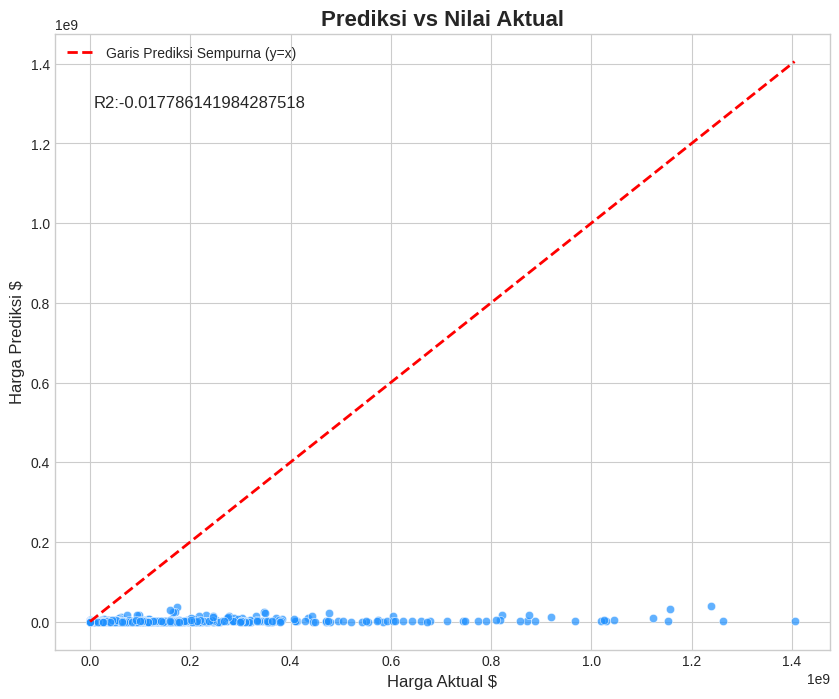

In [113]:
import matplotlib.pyplot as plt
import seaborn as sns

seaborn_version = 'seaborn-v0_8-whitegrid'
plt.figure(figsize=(10,8))
plt.style.use(seaborn_version)
sns.scatterplot(x=y_test, y=y_pred_rg, color = 'dodgerblue', alpha=0.7)
max_val = max(y_test.max(), y_pred_rg.max())
y_pred_rg.max()

plt.plot([0, max_val],[0, max_val], 'r--', lw=2, label='Garis Prediksi Sempurna (y=x)')
plt.title('Prediksi vs Nilai Aktual', fontsize=16, fontweight='bold')
plt.xlabel('Harga Aktual $', fontsize=12)
plt.ylabel('Harga Prediksi $', fontsize=12)
plt.legend()
plt.text(0.05, 0.9, f'R2:{r2_score_rg}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top')
plt.show()

**Random Forest**

In [105]:
model_RFR = TransformedTargetRegressor(
    regressor = RFR,
    func = np.log1p,
    inverse_func = np.expm1
)

In [106]:
pipeline_rfr = Pipeline([
    ('preprocessor',preprocessor),
    ('model', model_RFR)
])

In [107]:
params_grid ={
    'model__regressor__n_estimators': [50, 100, 200],
    'model__regressor__max_depth': [10, 20, 50, 100],
    'model__regressor__min_samples_split': [2, 5, 10],
}

In [108]:
grid_rf = GridSearchCV(
    estimator = pipeline_rfr,
    param_grid = params_grid,
    cv = kf,
    scoring = 'r2',
    n_jobs = -1,
    verbose = 1
)

In [109]:
grid_rf.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('log',
                                                                                          FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                                              inverse_func=<ufunc 'expm1'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['budget']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sp...
                                                          verbose_feature_names_out=False)),
                                       ('model',
                                        TransformedTargetRegressor(func=<ufunc 'log1p'>,
                                                                   inverse_func=<ufunc 'expm1'>,
                                                                   regressor=RandomForestRegressor(random_state=42)))]),
             n_jobs=-1,
             param_grid={'model__regressor__max_depth': [10, 20, 50, 100],
                         'model__regressor__min_samples_split': [2, 5, 10],
                         'model__regressor__n_estimators': [50, 100, 200]},
             scoring='r2', verbose=1)

In [114]:
best_RFR = grid_rf.best_estimator_

In [115]:
print('Best params yang ditemukan :', grid_rf.best_params_)
print('Best CV Score yang ditemukan :', grid_rf.best_score_)

Best params yang ditemukan : {'model__regressor__max_depth': 20, 'model__regressor__min_samples_split': 2, 'model__regressor__n_estimators': 50}
Best CV Score yang ditemukan : 0.5418680294291965


In [116]:
y_pred_rfr = best_RFR.predict(X_test)

In [117]:
from sklearn.metrics import r2_score

r2_score_rfr = r2_score(y_test, y_pred_rfr)
mae_rfr = mean_absolute_error(y_test, y_pred_rfr)
mse_rfr = mean_squared_error(y_test, y_pred_rfr)
rmse_rfr = np.sqrt(mse_rfr)

In [118]:
print("=== Evaluasi Model ===")
print(f"Score MAE adalah : {mae_rfr:.4f}")
print(f"Score MSE adalah : {mse_rfr:.4f}")
print(f"Score RMSE adalah : {rmse_rfr:.4f}")
print(f"Score R2 adalah : {r2_score_rfr:.4f}")

=== Evaluasi Model ===
Score MAE adalah : 8900251.0689
Score MSE adalah : 2083478721583889.2500
Score RMSE adalah : 45645139.0795
Score R2 adalah : 0.5597


In [136]:
best_rf_model = grid_rf.best_estimator_.named_steps['model'].regressor_
importances = best_rf_model.feature_importances_
prep = grid_rf.best_estimator_.named_steps['preprocessor']
feature_names = []
feature_names.extend(num_feat)
cat_transformer = prep.named_transformers_['cat']
if hasattr(cat_transformer, 'named_steps'):
  cat_encoder = cat_transformer.named_steps['encoder']
else:
  cat_encoder = cat_transformer

In [137]:
cat_feature_names = cat_encoder.get_feature_names_out(cat_feat).tolist()
feature_names.extend(cat_feature_names)
if hasattr(prep, 'remainder') and prep.remainder == 'passthrough':
  passthrough_cols = [col for col in X_train.columns if col not in num_feat and col not in cat_feat]
  feature_names.extend(passthrough_cols)

In [138]:
df_importances_rf = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by="Importance", ascending=False)

In [139]:
print("====== Top 10 Fitur importances Random Forest =======")
print(df_importances_rf.head(10))

====== Top 10 Fitur importances Random Forest =======
                                     Feature  Importance
0                                     budget    0.574913
55                              release_year    0.099828
56                             release_month    0.059312
57                         release_dayofweek    0.037236
22                       company_clean_other    0.012505
34                     belongs_to_collection    0.012367
38                                    Comedy    0.012269
41                                     Drama    0.012098
49                                   Romance    0.010481
31  countries_clean_United States of America    0.010240


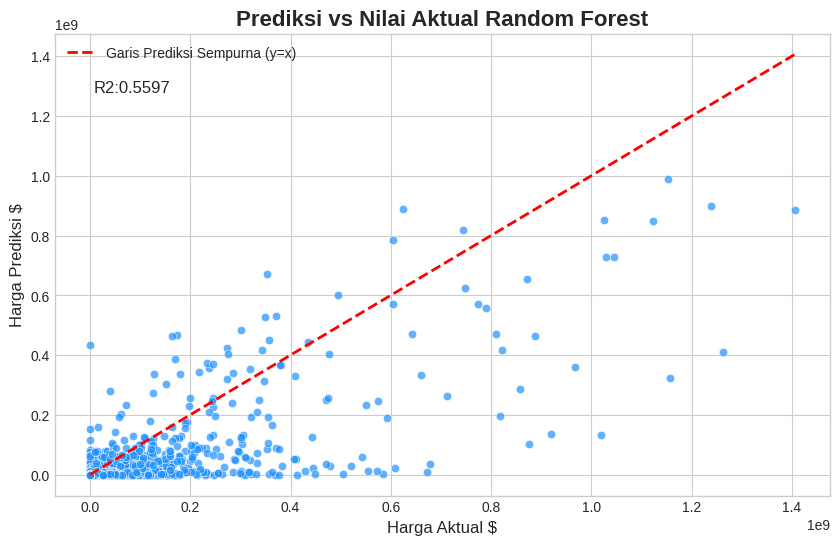

In [171]:
plt.figure(figsize=(10,6))
plt.style.use(seaborn_version)
sns.scatterplot(x=y_test, y=y_pred_rfr, color='dodgerblue', alpha=0.7)
max_val = max(y_test.max(), y_pred_rfr.max())
y_pred_rfr.max

plt.plot([0, max_val],[0, max_val], 'r--', lw=2, label='Garis Prediksi Sempurna (y=x)')
plt.title('Prediksi vs Nilai Aktual Random Forest', fontsize=16, fontweight='bold')
plt.xlabel('Harga Aktual $', fontsize=12)
plt.ylabel('Harga Prediksi $', fontsize=12)
plt.legend()
plt.text(0.05, 0.9, f'R2:{r2_score_rfr:.4f}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top')
plt.show()

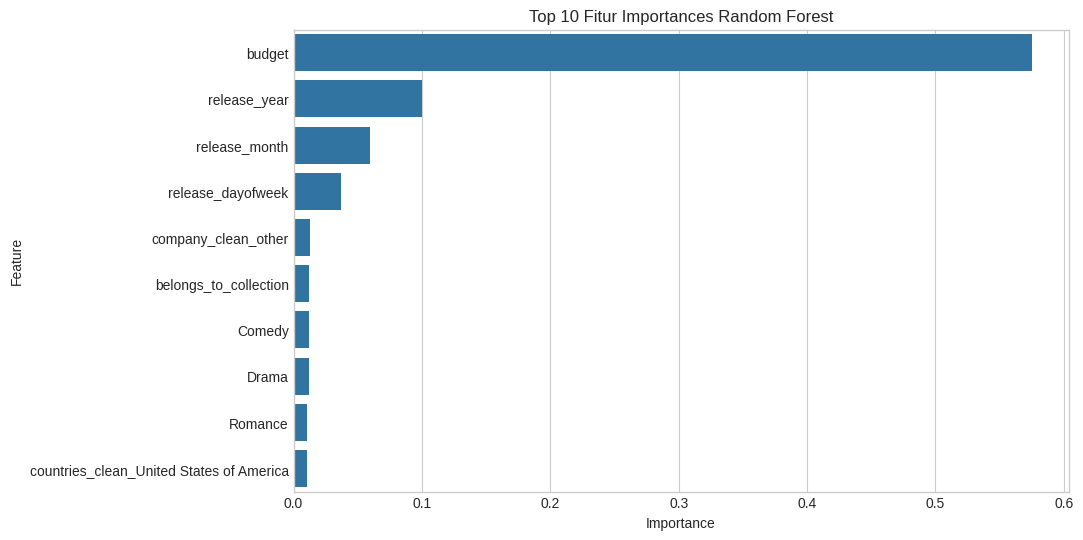

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=df_importances_rf.head(10))
plt.title('Top 10 Fitur Importances Random Forest')
plt.show()

**XGBOOST**

In [143]:
model_xgb = TransformedTargetRegressor(
    regressor = XGBR,
    func = np.log1p,
    inverse_func = np.expm1
)

In [144]:
pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model_xgb)
])

In [145]:
params_grid = {
    'model__regressor__n_estimators': [50, 100, 200, 300],
    'model__regressor__max_depth': [3, 10, 50, 100],
    'model__regressor__min_samples_split': [2, 5, 10, 20]
}

In [146]:
grid_xgb = GridSearchCV(
    estimator = pipeline_xgb,
    param_grid = params_grid,
    cv = kf,
    scoring = 'r2',
    n_jobs = -1,
    verbose = 1
)

In [147]:
grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 64 candidates, totalling 320 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [03:28:21] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "min_samples_split" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('log',
                                                                                          FunctionTransformer(func=<ufunc 'log1p'>,
                                                                                                              inverse_func=<ufunc 'expm1'>)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['budget']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore',
                                                                                       sp...
                                                                                          max_depth=None,
                                                                                          max_leaves=None,
                                                                                          min_child_weight=None,
                                                                                          missing=nan,
                                                                                          monotone_constraints=None,
                                                                                          multi_strategy=None,
                                                                                          n_estimators=None,
                                                                                          n_jobs=None,
                                                                                          num_parallel_tree=None, ...)))]),
             n_jobs=-1,
             param_grid={'model__regressor__max_depth': [3, 10, 50, 100],
                         'model__regressor__min_samples_split': [2, 5, 10, 20],
                         'model__regressor__n_estimators': [50, 100, 200, 300]},
             scoring='r2', verbose=1)

In [148]:
best_xgbr = grid_xgb.best_estimator_

In [149]:
print('Best params yang ditemukan :', grid_xgb.best_params_)
print('Best Score yang ditemukan :', grid_xgb.best_score_)

Best params yang ditemukan : {'model__regressor__max_depth': 50, 'model__regressor__min_samples_split': 2, 'model__regressor__n_estimators': 50}
Best Score yang ditemukan : 0.5062665657530931


In [150]:
y_pred_xgb = best_xgbr.predict(X_test)

In [151]:
mae_xgbr = mean_absolute_error(y_test, y_pred_xgb)
mse_xgbr = mean_squared_error(y_test, y_pred_xgb)
rmse_xgbr = np.sqrt(mse_xgbr)
r2_score_xgbr = r2_score(y_test, y_pred_xgb)

In [152]:
print("=== Evaluasi Model ===")
print(f"Score MAE adalah : {mae_xgbr:.4f}")
print(f"Score MSE adalah : {mse_xgbr:.4f}")
print(f"Score RMSE adalah : {rmse_xgbr:.4f}")
print(f"Score R2 adalah : {r2_score_xgbr:.4f}")

=== Evaluasi Model ===
Score MAE adalah : 8969468.0288
Score MSE adalah : 2166366158811248.7500
Score RMSE adalah : 46544238.7285
Score R2 adalah : 0.5422


In [160]:
best_xgbr_model = grid_xgb.best_estimator_.named_steps['model'].regressor_
importances_xgbr = best_model_xgbr.feature_importances_

In [161]:
prep_xgb = grid_xgb.best_estimator_.named_steps['preprocessor']
feature_names_xgb = []
feature_names_xgb.extend(num_feat)
cat_transformer_xgb = prep_xgb.named_transformers_['cat']
if hasattr(cat_transformer_xgb, 'named_steps'):
  cat_encoder_xgb = cat_transformer_xgb.named_steps['encoder']
else:
  cat_encoder_xgb = cat_transformer_xgb
cat_feature_names_xgb = cat_encoder_xgb.get_feature_names_out(cat_feat).tolist()
feature_names_xgb.extend(cat_feature_names_xgb)

In [164]:
if hasattr(prep_xgb, 'remainder') and prep_xgb.remainder == 'passthrough':
  passthrough_cols_xgb = [col for col in X_train.columns if col not in num_feat and col not in cat_feat]
  feature_names_xgb.extend(passthrough_cols_xgb)

In [165]:
df_importaces_xgb = pd.DataFrame({
    'feature': feature_names_xgb,
    'importance': importances_Xgb
}).sort_values(by="importance", ascending=False)

In [166]:
print("====== Top 10 Fitur Importances XGBoost =====")
print(df_importaces_xgb.head(10))

====== Top 10 Fitur Importances XGBoost =====
                                     feature  importance
0                                     budget    0.158071
22                       company_clean_other    0.074482
20             company_clean_Unknown_company    0.069425
26                     countries_clean_India    0.044895
51                                  TV Movie    0.032256
31  countries_clean_United States of America    0.024343
16          company_clean_RKO Radio Pictures    0.020181
29                    countries_clean_Russia    0.017700
18              company_clean_United Artists    0.017446
28                     countries_clean_Japan    0.017231


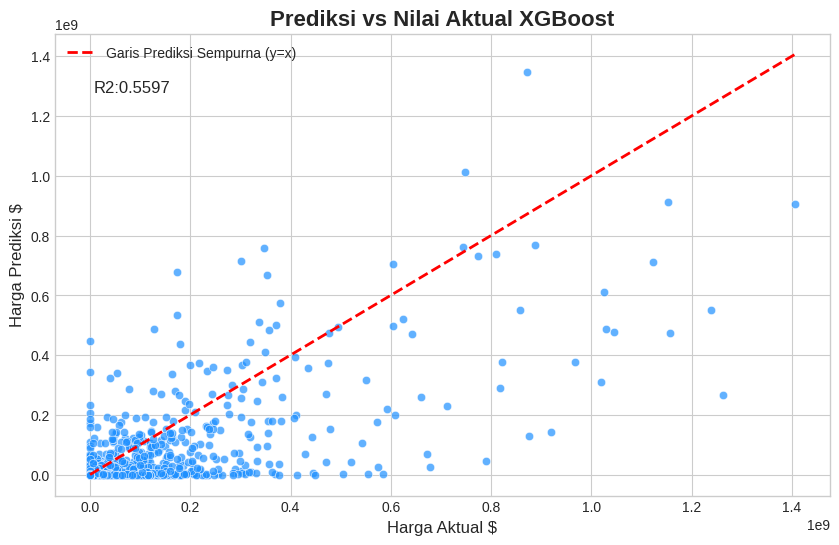

In [169]:
plt.figure(figsize=(10,6))
plt.style.use(seaborn_version)
sns.scatterplot(x=y_test, y=y_pred_xgb, color='dodgerblue', alpha=0.7)
max_val = max(y_test.max(), y_pred_xgb.max())
y_pred_xgb.max

plt.plot([0, max_val],[0, max_val], 'r--', lw=2, label='Garis Prediksi Sempurna (y=x)')
plt.title('Prediksi vs Nilai Aktual XGBoost', fontsize=16, fontweight='bold')
plt.xlabel('Harga Aktual $', fontsize=12)
plt.ylabel('Harga Prediksi $', fontsize=12)
plt.legend()
plt.text(0.05, 0.9, f'R2:{r2_score_rfr:.4f}', transform=plt.gca().transAxes, fontsize=12, verticalalignment='top')
plt.show()

/tmp/ipykernel_3353/572059762.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=df_importaces_xgb.head(10), palette='viridis')


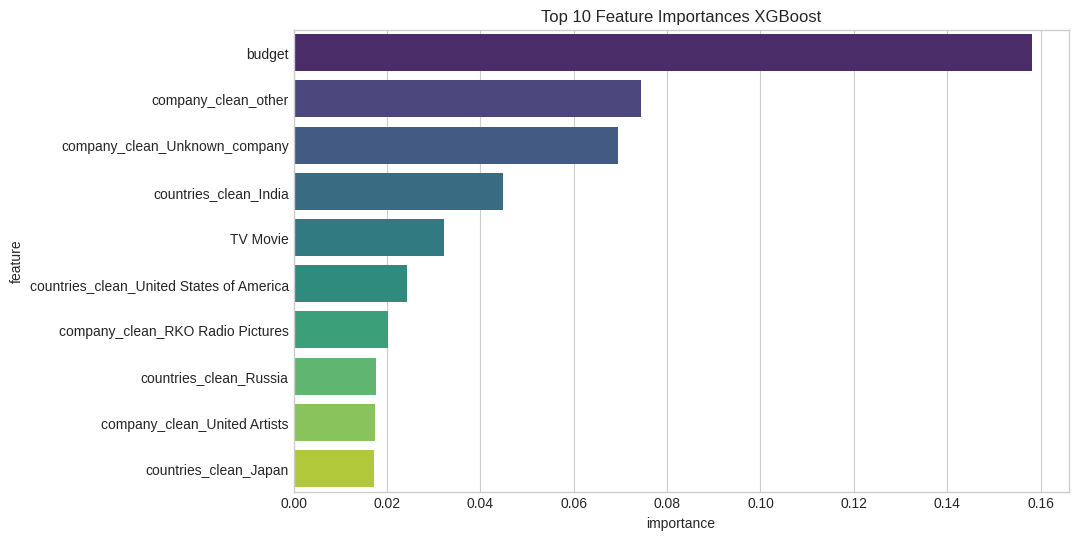

In [170]:
plt.figure(figsize=(10,6))
sns.barplot(x='importance', y='feature', data=df_importaces_xgb.head(10), palette='viridis')
plt.title('Top 10 Feature Importances XGBoost')
plt.show()

In [172]:
import joblib
from google.colab import files

joblib.dump(best_RFR, 'model_RFR_revenue.joblib')
joblib.dump(best_xgbr, 'model_XGBR_revenue.joblib')
files.download('model_XGBR_revenue.joblib')
files.download('model_RFR_revenue.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>